# 2-01 주가 변동성 시나리오 — 과거 일별 수익률을 다시 뽑아 그린 가격 범위

**질문 예시:** "삼성전자 1년 뒤 주가가 어느 범위에 있을 수 있어?", "이 종목 변동성이면 6개월에 얼마나 빠질 수 있어?"

> ⚠️ **예측이 아닙니다.** 과거 일별 수익률을 무작위로 다시 뽑아 "과거만큼 출렁인다면 이 정도 범위"를 보여 주는
> **변동성 시나리오**입니다. 실적·금리·수급·뉴스는 전혀 들어 있지 않고, 가운데 선(중앙값)은 목표가가 아닙니다.

옛 `krxnewsscrap/predictprice.py`(Streamlit "주가 예측" 앱)를 다시 만들었습니다. 원래 앱에는 이런 문제가 있었습니다.

| 옛 앱 | 문제 | 이 노트북 |
|---|---|---|
| ARIMA·선형회귀 | statsmodels/sklearn이 없으면 **조용히 직선 추세로 대체** | 모델 이름만 바꾼 대체 없음. 쓰는 방법은 하나(부트스트랩)뿐 |
| "LSTM (간단버전)" | 실제로는 이동평균 + 잡음 | 삭제 |
| Monte Carlo | 시드 없는 **경로 1개** | 시드 고정, 경로 10,000개의 **분위수(5·25·50·75·95%)** |
| 미래 날짜 | 거래일 수익률 547개를 **달력일**에 붙여 "1.5년 후"가 실제로는 약 2.2년 | 가로축을 **거래일**로 (252거래일 ≈ 1년) |
| 정규분포 가정 | 평균·표준편차로 정규난수 | 실제 일별 수익률을 그대로 재추출(두꺼운 꼬리 유지) |

쓰는 엔드포인트: `listed_stocks`(단축코드 → 표준코드), `individual_price_trend`(개별종목 시세추이, **수정주가**)

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/krx-data-api/blob/main/scenarios/2_stock_price/01_price_scenario_fan.ipynb)

## 0. 준비
2026-09부터 KRX는 로그인하지 않은 요청을 거절합니다. Colab 왼쪽 🔑(Secrets)에 `KRX_ID`, `KRX_PW`(KRX 정보데이터시스템 계정)를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다). 계정 값은 출력하지 않습니다.

In [1]:
# Colab에서만: krx-data-api 와 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install git+https://github.com/beaten-by-the-market/krx-data-api.git koreanize-matplotlib

In [2]:
# ── KRX 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────────────
# 2026-09부터 KRX는 비로그인 요청을 거절합니다. KRX 정보데이터시스템 계정이 필요합니다.
# Colab: 왼쪽 🔑(Secrets)에 KRX_ID, KRX_PW 를 넣고 "노트북 액세스"를 켜세요.
#        Secrets에 없으면 입력창으로 묻습니다. 아이디·비밀번호는 출력하지 않습니다.
# 로컬: krx_data_api 가 작업 폴더의 .env(또는 패키지를 클론한 레포의 .env)에서 KRX_ID/KRX_PW 를 읽습니다.
import os, sys
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from getpass import getpass
    for _k in ("KRX_ID", "KRX_PW"):
        if os.environ.get(_k):
            continue
        try:
            from google.colab import userdata
            _v = userdata.get(_k)
        except Exception:
            _v = None
        os.environ[_k] = _v or getpass(f"{_k}: ")

from krx_data_api import fetch  # noqa: E402  (import 시 .env 로드)
from krx_data_api.daily_snapshots import trading_days  # noqa: E402

if not (os.environ.get("KRX_ID") and os.environ.get("KRX_PW")):
    raise RuntimeError("KRX_ID / KRX_PW 가 없습니다. Colab Secrets 또는 .env 에 넣어 주세요.")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)


def num(s):
    """KRX JSON의 '1,234' 같은 콤마 문자열 → 숫자. '-'·빈 값은 NaN."""
    return pd.to_numeric(pd.Series(s).astype(str).str.replace(",", "", regex=False).str.strip(),
                         errors="coerce")


def ymd(d):
    """날짜 → 'YYYYMMDD' (KRX 파라미터 형식)."""
    return pd.Timestamp(d).strftime("%Y%m%d")


def last_trading_day(asof=None):
    """asof(기본 오늘) 또는 그 이전의 마지막 매매거래일 → Timestamp.
    KRX는 휴장일 trdDd에 직전 거래일 데이터를 그대로 주므로 날짜를 이걸로 맞춰 씁니다."""
    end = pd.Timestamp(asof or date.today())
    days = trading_days(ymd(end - timedelta(days=14)), ymd(end))
    return pd.Timestamp(days[-1])


def eok(won, digits=0):
    """원 → 억원 숫자."""
    return (pd.Series(won) / 1e8).round(digits)


# 한글 차트 폰트
import matplotlib.pyplot as plt  # noqa: E402
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("KRX 준비 완료", "(Colab)" if IN_COLAB else "(로컬)", "· 로그인 계정 설정됨")

KRX 준비 완료 (로컬) · 로그인 계정 설정됨


In [3]:
CODE = "005930"          # 단축코드 (삼성전자)
ASOF = "2026-11-24"      # 기준일 (이날까지의 시세 사용)
LOOKBACK_YEARS = 3       # 수익률을 뽑을 과거 기간
HORIZON = 378            # 시뮬레이션 거래일 수 (378 ≈ 1.5년, 옛 앱의 "1.5년 후"와 맞춤)
N_SIMS = 10_000          # 경로 수
SEED = 42                # 난수 시드 (같은 값이면 같은 결과)
PCTS = [5, 25, 50, 75, 95]

## 1. 종목 찾기
`individual_price_trend`는 표준코드(ISIN, `KR7…`)를 받습니다. `listed_stocks`(JSON)의 `ISU_SRT_CD`(단축코드)로 `ISU_CD`(표준코드)를 찾습니다.

In [4]:
listed = fetch("listed_stocks")
row = listed.loc[listed["ISU_SRT_CD"] == CODE]
if row.empty:
    raise ValueError(f"{CODE}: 현재 상장 종목에 없습니다")
row = row.iloc[0]
ISIN, NAME = row["ISU_CD"], row["ISU_ABBRV"]
print(f"{NAME} ({CODE}) · 표준코드 {ISIN} · {row['MKT_TP_NM']} · {row['KIND_STKCERT_TP_NM']}")

삼성전자 (005930) · 표준코드 KR7005930003 · KOSPI · 보통주


## 2. 수정주가 받기
`adjusted_price=True`(수정주가)를 씁니다. 액면분할·병합·증자 권리락이 있으면 원주가는 그날 가짜 급락·급등이 생겨
수익률 분포를 왜곡하기 때문입니다. 수정 기준일(`adjBasDd`)은 기준일로 고정합니다.
현금배당은 수정 대상이 아닙니다(삼성전자 2023-11~2026-11 수정주가와 원주가가 733거래일 모두 같았음, 분기배당이 있는데도). 그래서 배당락일의 하락은 수익률에 그대로 들어가고, 배당 수입은 빠집니다.

In [5]:
end = pd.Timestamp(ASOF)
start = end - pd.DateOffset(years=LOOKBACK_YEARS)
px = fetch("individual_price_trend", isuCd=ISIN, strtDd=ymd(start), endDd=ymd(end),
           adjusted_price=True, adjBasDd=ymd(end))
px["일자"] = pd.to_datetime(px["일자"], format="%Y/%m/%d")
px = px.sort_values("일자").set_index("일자")
close = px["종가"].astype(float)
r = np.log(close).diff().dropna()      # 일별 로그수익률
LAST = close.iloc[-1]
print(f"{close.index[0].date()} ~ {close.index[-1].date()} · {len(close)}거래일 · 마지막 종가 {LAST:,.0f}원")
print(f"거래량 0인 날(거래정지 등, 수익률 0으로 들어감): {(px['거래량'] == 0).sum()}일")

2023-11-24 ~ 2026-11-24 · 729거래일 · 마지막 종가 189,400원
거래량 0인 날(거래정지 등, 수익률 0으로 들어감): 0일


In [6]:
def stats(x):
    return pd.Series({
        "거래일수": len(x),
        "일평균(%)": x.mean() * 100,
        "일표준편차(%)": x.std() * 100,
        "연환산 평균(%)": x.mean() * 252 * 100,
        "연환산 변동성(%)": x.std() * np.sqrt(252) * 100,
        "최대 하락일(%)": (np.exp(x.min()) - 1) * 100,
        "최대 상승일(%)": (np.exp(x.max()) - 1) * 100,
        "초과첨도": x.kurt(),
    }).round(2)

stats(r).to_frame(f"{NAME} 일별 로그수익률").T

,거래일수,일평균(%),일표준편차(%),연환산 평균(%),연환산 변동성(%),최대 하락일(%),최대 상승일(%),초과첨도
삼성전자 일별 로그수익률,728.0,0.13,3.3,33.62,52.37,-13.39,26.81,5.9


## 3. 시뮬레이션 — 과거 일별 수익률 부트스트랩
과거 일별 로그수익률 중에서 **복원추출로 하루치씩 뽑아** `HORIZON`거래일을 이어 붙입니다. 이걸 `N_SIMS`번 반복합니다.

기본은 **평균 제거(드리프트 0)** 입니다. 과거 3년 동안 크게 올랐다면 그 평균 상승률을 그대로 쓰는 순간
"앞으로도 그만큼 오른다"는 가정을 몰래 넣는 셈이기 때문입니다. 평균을 빼면 중앙값 경로는 현재가 근처에 머물고,
폭(변동성)만 남습니다. 비교용으로 과거 평균을 그대로 둔 결과도 아래 표에 함께 냅니다.

In [7]:
def simulate(returns, horizon, n, seed, demean=True):
    """일별 로그수익률을 복원추출해 누적한 가격 배수 경로 (n × (horizon+1)), 첫 열은 1."""
    x = returns.to_numpy()
    if demean:
        x = x - x.mean()
    rng = np.random.default_rng(seed)
    draws = x[rng.integers(0, len(x), size=(n, horizon))]
    return np.exp(np.hstack([np.zeros((n, 1)), np.cumsum(draws, axis=1)]))

paths = simulate(r, HORIZON, N_SIMS, SEED, demean=True)
paths_drift = simulate(r, HORIZON, N_SIMS, SEED, demean=False)
fan = pd.DataFrame(np.percentile(paths, PCTS, axis=0).T * LAST, columns=[f"p{p}" for p in PCTS])
fan.index.name = "거래일"
fan.iloc[[0, 21, 63, 126, 252, HORIZON]].round(0)

,p5,p25,p50,p75,p95
거래일,,,,,
0,189400.0,189400.0,189400.0,189400.0,189400.0
21,147617.0,171480.0,189081.0,208375.0,242367.0
63,122477.0,158902.0,189340.0,225489.0,289807.0
126,102768.0,146817.0,188174.0,241926.0,350928.0
252,79557.0,132522.0,188810.0,267637.0,453613.0
378,66432.0,123001.0,186977.0,290394.0,543742.0


## 4. 가격 범위 그림 (가로축 = 거래일)
왼쪽은 최근 1년(252거래일) 실제 수정주가, 오른쪽은 시나리오 분위수입니다. 짙은 띠가 25~75%, 옅은 띠가 5~95%입니다.
세로축은 로그 눈금이라 같은 비율의 등락(예: −50%와 +100%)이 같은 높이로 보입니다.

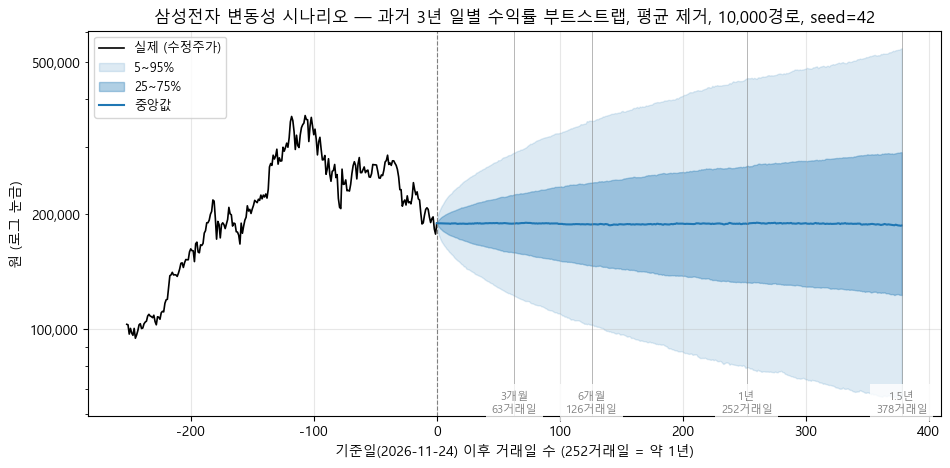

In [8]:
hist = close.iloc[-253:]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(np.arange(-len(hist) + 1, 1), hist.values, color="black", lw=1.2, label="실제 (수정주가)")
d = fan.index.to_numpy()
ax.fill_between(d, fan["p5"], fan["p95"], color="tab:blue", alpha=.15, label="5~95%")
ax.fill_between(d, fan["p25"], fan["p75"], color="tab:blue", alpha=.35, label="25~75%")
ax.plot(d, fan["p50"], color="tab:blue", lw=1.5, label="중앙값")
ax.axvline(0, color="gray", ls="--", lw=.8)
ax.set_yscale("log")  # 같은 비율의 등락이 같은 높이로 보이게 (−50%와 +100%가 대칭)
for t, lab in [(63, "3개월"), (126, "6개월"), (252, "1년"), (378, "1.5년")]:
    if t <= HORIZON:
        ax.axvline(t, color="gray", lw=.4)
        ax.text(t, ax.get_ylim()[0], f"{lab}\n{t}거래일", ha="center", va="bottom", fontsize=8, color="gray",
                bbox=dict(fc="white", ec="none", alpha=.8))
ax.set_xlabel(f"기준일({end.date()}) 이후 거래일 수 (252거래일 = 약 1년)")
ax.set_ylabel("원 (로그 눈금)")
ax.set_title(f"{NAME} 변동성 시나리오 — 과거 {LOOKBACK_YEARS}년 일별 수익률 부트스트랩, 평균 제거, {N_SIMS:,}경로, seed={SEED}")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}" if str(int(v))[0] in "25" else ""))
ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=.3)

## 5. 기간별 범위와 하락 확률
같은 시드로 **평균 제거**와 **과거 평균 유지**를 나란히 봅니다. 두 결과의 차이가 곧 "과거 추세를 미래에 그대로 넣었을 때"의 효과입니다.

In [9]:
def horizon_table(p, label):
    rows = []
    for t, lab in [(21, "1개월"), (63, "3개월"), (126, "6개월"), (252, "1년"), (378, "1.5년")]:
        if t > HORIZON:
            continue
        v = p[:, t]
        q = np.percentile(v, PCTS)
        rows.append({"가정": label, "기간": f"{lab}({t}거래일)",
                     **{f"{k}% 가격": f"{LAST * x:,.0f}" for k, x in zip(PCTS, q)},
                     "5~95% 수익률": f"{(q[0] - 1) * 100:+.0f}% ~ {(q[-1] - 1) * 100:+.0f}%",
                     "하락 확률": f"{(v < 1).mean() * 100:.0f}%",
                     "−30% 이하 확률": f"{(v <= 0.7).mean() * 100:.1f}%"})
    return pd.DataFrame(rows)

pd.concat([horizon_table(paths, "평균 제거"), horizon_table(paths_drift, "과거 평균 유지")], ignore_index=True)

,가정,기간,5% 가격,25% 가격,50% 가격,75% 가격,95% 가격,5~95% 수익률,하락 확률,−30% 이하 확률
0,평균 제거,1개월(21거래일),"147,617","171,480","189,081","208,375","242,367",-22% ~ +28%,50%,0.9%
1,평균 제거,3개월(63거래일),"122,477","158,902","189,340","225,489","289,807",-35% ~ +53%,50%,8.8%
2,평균 제거,6개월(126거래일),"102,768","146,817","188,174","241,926","350,928",-46% ~ +85%,51%,17.2%
3,평균 제거,1년(252거래일),"79,557","132,522","188,810","267,637","453,613",-58% ~ +139%,50%,25.0%
4,평균 제거,1.5년(378거래일),"66,432","123,001","186,977","290,394","543,742",-65% ~ +187%,51%,28.9%
5,과거 평균 유지,1개월(21거래일),"151,812","176,353","194,454","214,297","249,254",-20% ~ +32%,43%,0.6%
6,과거 평균 유지,3개월(63거래일),"133,218","172,837","205,944","245,263","315,222",-30% ~ +66%,38%,4.9%
7,과거 평균 유지,6개월(126거래일),"121,582","173,696","222,625","286,218","415,176",-36% ~ +119%,33%,7.8%
8,과거 평균 유지,1년(252거래일),"111,354","185,489","264,274","374,607","634,913",-41% ~ +235%,26%,9.3%
9,과거 평균 유지,1.5년(378거래일),"110,007","203,682","309,621","480,874","900,402",-42% ~ +375%,21%,9.2%


## 6. 과거 기간을 바꾸면 폭이 얼마나 달라지나
변동성은 시기마다 다릅니다. 최근 1년만 쓰면 최근의 출렁임이, 3년을 쓰면 더 긴 평균이 반영됩니다. 어느 쪽이 "맞다"고 할 수 없어서 같이 봅니다.

In [10]:
rows = []
for yrs in (1, 2, LOOKBACK_YEARS):
    sub = r[r.index > end - pd.DateOffset(years=yrs)]
    p = simulate(sub, 252, N_SIMS, SEED, demean=True)[:, 252]
    q = np.percentile(p, [5, 50, 95])
    rows.append({"과거 기간": f"최근 {yrs}년", "거래일수": len(sub),
                 "연환산 변동성(%)": round(sub.std() * np.sqrt(252) * 100, 1),
                 "1년 뒤 5%": f"{LAST * q[0]:,.0f}", "1년 뒤 중앙값": f"{LAST * q[1]:,.0f}", "1년 뒤 95%": f"{LAST * q[2]:,.0f}"})
pd.DataFrame(rows).drop_duplicates("과거 기간")

,과거 기간,거래일수,연환산 변동성(%),1년 뒤 5%,1년 뒤 중앙값,1년 뒤 95%
0,최근 1년,244,78.1,"52,159","188,470","686,628"
1,최근 2년,486,60.1,"71,449","188,049","498,881"
2,최근 3년,728,52.4,"80,807","188,641","447,741"


## 결과 읽는 법과 한계
- **이건 예측이 아니라 변동성의 크기를 가격으로 옮긴 그림입니다.** "5~95% 띠"는 과거 수익률이 앞으로도 같은 분포에서 나온다는 가정 아래의 범위일 뿐, 실제 주가가 이 안에 있을 확률이 90%라는 뜻이 아닙니다.
- **하루하루를 독립으로 뽑습니다.** 변동성이 몰리는 시기(급락 뒤 큰 변동이 이어지는 현상)와 추세·평균회귀를 무시합니다. 위기 국면에서는 실제 꼬리가 이 그림보다 두껍습니다.
- **과거 기간 선택이 결과를 크게 바꿉니다**(6장). 기간을 바꿔 가며 보는 것이 맞습니다.
- **평균 제거 버전의 중앙값은 현재가 근처**입니다. 상승·하락 전망을 담지 않았다는 뜻이지, 주가가 그대로라는 예측이 아닙니다.
- 수정주가는 분할·증자를 반영하지만 **현금배당은 반영하지 않습니다.** 배당락 하락은 수익률에 들어가고 배당금은 빠지므로, 배당이 큰 종목은 총수익 기준보다 범위가 조금 아래로 치우칩니다.
- 가로축은 거래일입니다. 달력 날짜로 바꾸려면 휴장일 달력이 필요하고, 대략 252거래일 ≈ 1년, 21거래일 ≈ 1개월로 읽으면 됩니다.